In [8]:
import lmfit
import matplotlib.pyplot as plt
import numpy as np


def fitten_pulseheight(file, cutoff1, cutoff2):
    pulseheight_list = []
    counts = []
    with open(file) as input:
        next(input)

    
        for line in input:
            data_cut = line.split(",")
            pulseheight = float(data_cut[0])
            if pulseheight >= cutoff1 and pulseheight <= cutoff2 :
                pulseheight_list.append(float(data_cut[0]))
                counts.append(float(data_cut[2]))

    counts = np.array(counts)
    pulseheight = np.array(pulseheight_list)

    mod = lmfit.models.GaussianModel()
    params = mod.guess(counts, x=pulseheight)
    fit_result = mod.fit(counts, params, x=pulseheight)

    area = fit_result.params['amplitude'].value

    print(f"area= {area} ")

    uncertainty = fit_result.params["fwhm"].value

    pulseheight_max = fit_result.params["center"].value
    print(f"the peak is at a pulsheight of {pulseheight_max} mV")

    plt.plot(pulseheight, counts)
    plt.plot(pulseheight, fit_result.best_fit)
    plt.title(file)
    plt.xlabel("pulseheight [mV]")
    plt.ylabel("counts")
    plt.grid(True)
    plt.show()
    return pulseheight_max, uncertainty, pulseheight_list, counts




area= 2990.1212101654824 
the peak is at a pulsheight of 205.6216437220518 mV


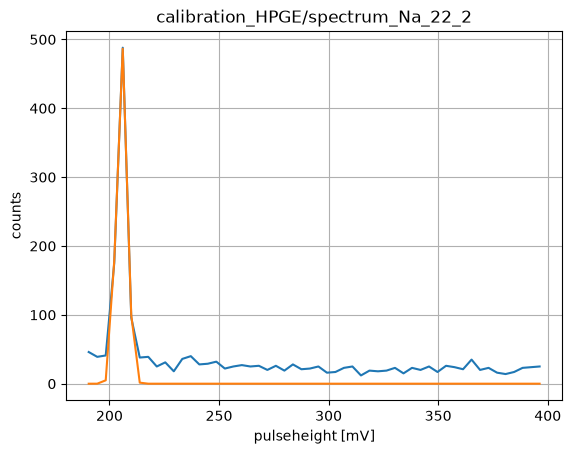

area= 22484.179995802562 
the peak is at a pulsheight of 265.5493523736855 mV


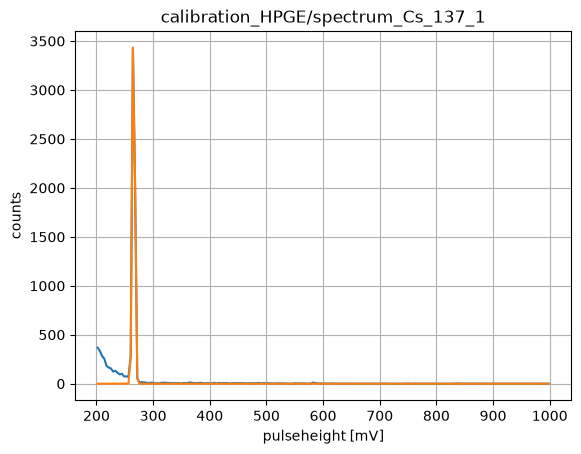

area= 3163.509306335188 
the peak is at a pulsheight of 533.0052019083884 mV


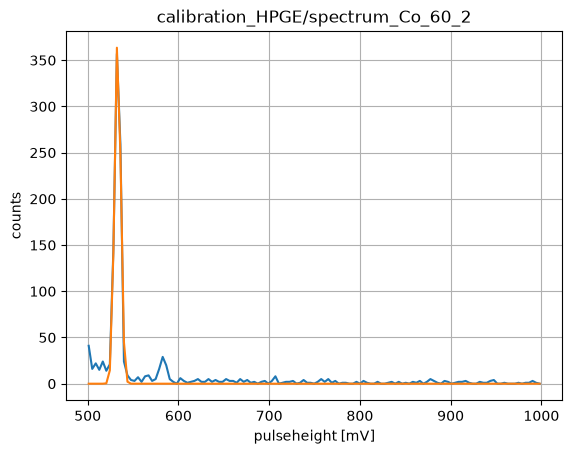

In [9]:

pulseheight_Na, fwhm_Na, pulseheight_list_Na, counts_Na = fitten_pulseheight(
    "calibration_HPGE/spectrum_Na_22_2", 190,400
)
pulseheight_Cs1, fwhm_Cs1, pulse_height_list_Cs1, counts_Cs1 = fitten_pulseheight(
    "calibration_HPGE/spectrum_Cs_137_1", 200,1000
)

pulseheight_Co2, fwhm_C02, pulseheight_list_Co2, counts_Co2 = fitten_pulseheight(
    "calibration_HPGE/spectrum_Co_60_2", 500,1000
)
pulseheight_array = np.array(
    [pulseheight_Na, pulseheight_Cs1, pulseheight_Co2]
)


[[Model]]
    Model(linear_mod)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 7
    # data points      = 3
    # variables        = 2
    chi-square         = 0.00780147
    reduced chi-square = 0.00780147
    Akaike info crit   = -13.8561665
    Bayesian info crit = -15.6589419
    R-squared          = 0.99999937
[[Variables]]
    a:  2.50876051 +/- 0.00257168 (0.10%) (init = 5)
    b: -4.54031912 +/- 0.81659896 (17.99%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(a, b) = -0.9270
a = 2.5087605100267396
b = -4.540319124784413


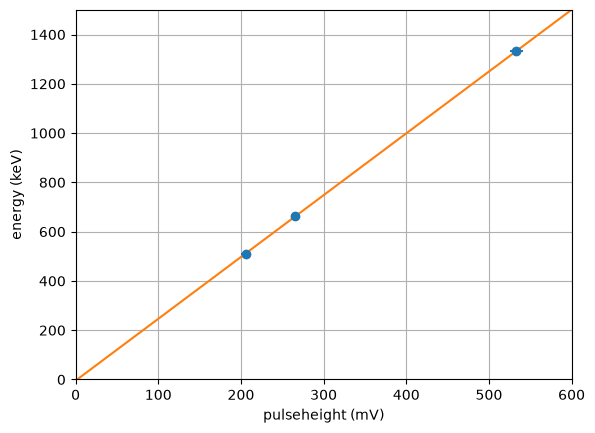

In [10]:

Energy_list = [510.99, 662, 1332.5]
Energy_array = np.array(Energy_list)
pulseheight_fwhm = np.array([fwhm_Na, fwhm_Cs1, fwhm_C02])


def linear_mod(x, a, b):
    return a * x + b


mod = lmfit.Model(linear_mod)
fit_result = mod.fit(
    Energy_array, a=5, b=0, x=pulseheight_array, weights=1 / pulseheight_fwhm
)
print(fit_result.fit_report())

a = fit_result.best_values["a"]
b = fit_result.best_values["b"]

print(f"a = {a}")
print(f"b = {b}")

x = np.linspace(0, 600, 100)
y = a * x + b

plt.errorbar(pulseheight_array, Energy_array, xerr=pulseheight_fwhm, fmt="o")
plt.plot(x, y)
plt.xlabel("pulseheight (mV)")
plt.ylabel("energy (keV)")
plt.xlim(0, 600)
plt.ylim(0, 1500)
plt.grid(True)
plt.show()



In [ ]:

def fitten_Energy(list_pulseheight, list_counts, a, b):
    # used the found parameters and claculates the energy for every count
    Energy_list = []
    counts = []
    for I in range(len(list_counts)):
        pulseheight = float(list_pulseheight[I])
        count = list_counts[I]
        Energy = a * pulseheight + b
        Energy_list.append(Energy)
        counts.append(count)

    counts = np.array(counts)
    Energy_list = np.array(Energy_list)

    # fits the graph and gives the fwhm (uncertainty) and the max energy
    mod = lmfit.models.GaussianModel()
    params = mod.guess(counts, x=Energy_list)
    fit_result = mod.fit(counts, params, x=Energy_list)

    uncertainty = fit_result.params["fwhm"].value

    energy_max = fit_result.params["center"].value
    
    # plots the graph of the energy
    plt.plot(Energy_list, counts)
    plt.plot(Energy_list, fit_result.best_fit)
    plt.xlabel("energy [keV]")
    plt.ylabel("counts")
    plt.grid(True)
    plt.show()

    print(f"the peak is at a energy of {energy_max} keV")

    return uncertainty



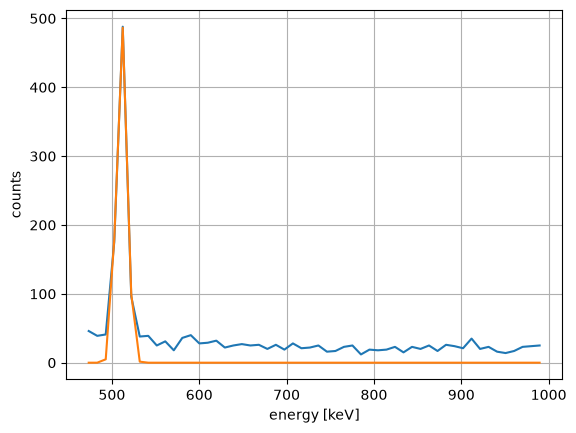

the peak is at a energy of 511.3151405065953 keV
resolution_Na_22_ = 2.7882488510977685 en fmwh_Na = 14.247672804224488


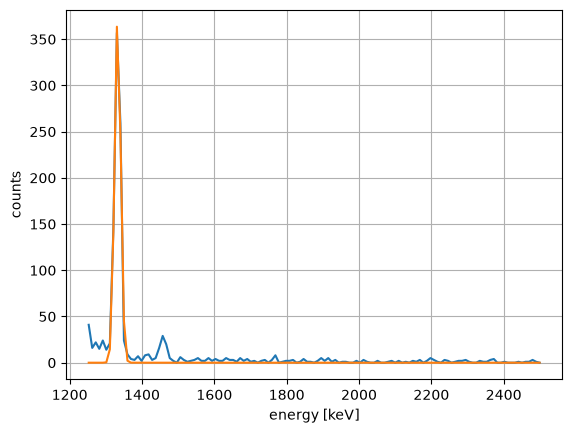

the peak is at a energy of 1332.6420828946934 keV
resolution_Co_60_2 = 1.695975627317902 en fmwh_Co_2 = 19.897186059693627


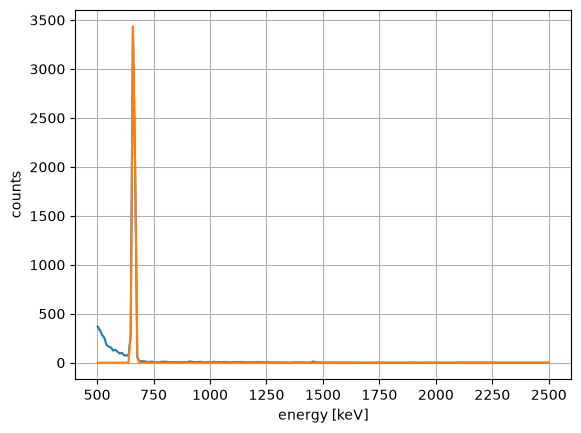

the peak is at a energy of 661.6594095903968 keV
resolution_Cs_137_1 = 1.990967366539623 en fmwh_Cs_137_1 = 13.180203966492305


In [ ]:

# calculates the resolution of Sodium by taking the half width and the known value and than gives the resolution
fmwh_Na = fitten_Energy(pulseheight_list_Na, counts_Na, a, b)
resolution_Na = fmwh_Na / 510.99 * 100
print(f"resolution_Na_22_ = {resolution_Na} en fmwh_Na = {fmwh_Na}")

# calculates the resolution of Cobalt by taking the half width and the known value and than gives the resolution
fmwh_Co_2 = fitten_Energy(pulseheight_list_Co2, counts_Co2, a, b)
resolution_Co2 = fmwh_Co_2 / 1173.2 * 100
print(f"resolution_Co_60_2 = {resolution_Co2} en fmwh_Co_2 = {fmwh_Co_2}")

# calculates the resolution of Cesium by taking the half width and the known value and than gives the resolution
fmwh_Cs_1 = fitten_Energy(pulse_height_list_Cs1, counts_Cs1, a, b)
resolution_Cs1 = fmwh_Cs_1 / 662 * 100
print(f"resolution_Cs_137_1 = {resolution_Cs1} en fmwh_Cs_137_1 = {fmwh_Cs_1}")



